# Упражнения по Boosting and Stacking 

![Boosting.png](Assets/Boosting.png)

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

Мы будем использовать базу данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированную на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearnex import patch_sklearn

patch_sklearn()

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

data_path = ['data']

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и проанализируйте структуру и типы данных. Типов данных будет слишком много, чтобы перечислять их по каждому столбцу отдельно. Вместо этого сгруппируйте типы по количеству.
* Определите, требуется ли масштабирование столбцов с числами типа float.

In [2]:
filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')
data.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


В наборе данных довольно много столбцов с предикторами.

In [3]:
print('Размерность:', data.shape)
print('Пропусков:', data.isna().sum().sum())
print('Дубликатов строк:', data.duplicated().sum())

Размерность: (10299, 562)
Пропусков: 0


Дубликатов строк: 0


И все они — значения типа float. Единственное значение, не относящееся к типу float, — это столбец «categories», который и является объектом прогнозирования.

In [4]:
print(data.dtypes.value_counts())
data.select_dtypes(exclude='float').columns.tolist()

float64    561
str          1
Name: count, dtype: int64


['Activity']

Минимальное и максимальное значения для столбцов типа float составляют -1,0 и 1,0 соответственно. Однако для методов, основанных на дереве, масштабирование никогда не требуется.

In [5]:
float_columns = data.select_dtypes('float').columns
float_columns_range = data[float_columns].agg(['min', 'max']).T
float_columns_range.describe().loc[['min', 'max']]

,min,max
min,-1.0,1.0
max,-1.0,1.0


**Вывод по вопросу 1.** В наборе 10299 записей и 562 столбца, пропусков и дубликатов нет.

- 561 столбец имеет тип `float64`, это признаки.
- Единственный нечисловой столбец - строковый `Activity`, это целевая переменная.
- У каждого float-столбца минимум равен -1.0, а максимум 1.0, то есть признаки уже нормализованы в диапазон [-1, 1].

Для моделей на основе деревьев (градиентный бустинг, AdaBoost) масштабирование не нужно, так как разбиения зависят только от порядка значений признака. Для логистической регрессии в вопросе 6 дополнительная стандартизация тоже не обязательна, потому что все признаки уже приведены к одному диапазону.

## Вопрос 2

* Присвойте действиям целочисленные коды.
* Разделите данные на обучающий и тестовый наборы. Решите, будет ли производиться стратификация данных при разделении на обучающий и тестовый наборы или нет.

**ПРИМЕЧАНИЕ**: Мы собираемся создать обучающий и тестовый наборы данных из `data`. На этих наборах данных мы будем проводить поиск по сетке с различными значениями параметров. Это может занять некоторое время. Чтобы сократить время поиска по сетке, вы можете уменьшить разрешение `data` и создать `X_train, X_test, y_train, y_test` на основе набора данных с уменьшенным разрешением.

Теперь разделите данные на обучающий и тестовый наборы. Здесь не использовалось стратифицированное деление. Если возникнут проблемы с какими-либо метриками ошибок на тестовом наборе, может быть целесообразно начать подбор модели с использованием стратифицированного деления. Однако метод бустинга является довольно мощной моделью, поэтому в данном случае это может оказаться ненужным.

In [6]:
X = data.drop(columns='Activity')
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data['Activity'])
class_names = label_encoder.classes_
dict(enumerate(class_names))

{0: 'LAYING',
 1: 'SITTING',
 2: 'STANDING',
 3: 'WALKING',
 4: 'WALKING_DOWNSTAIRS',
 5: 'WALKING_UPSTAIRS'}

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print('Train:', X_train.shape, 'Test:', X_test.shape)

pd.DataFrame({
    'all': pd.Series(y).value_counts(normalize=True),
    'train': pd.Series(y_train).value_counts(normalize=True),
    'test': pd.Series(y_test).value_counts(normalize=True),
}).sort_index().set_axis(class_names).round(3)

Train: (7209, 561) Test: (3090, 561)


,all,train,test
LAYING,0.189,0.187,0.193
SITTING,0.173,0.168,0.182
STANDING,0.185,0.189,0.177
WALKING,0.167,0.164,0.174
WALKING_DOWNSTAIRS,0.137,0.137,0.136
WALKING_UPSTAIRS,0.150,0.155,0.137


**Вывод по вопросу 2.** `LabelEncoder` присвоил коды в алфавитном порядке: 0 - LAYING, 1 - SITTING, 2 - STANDING, 3 - WALKING, 4 - WALKING_DOWNSTAIRS, 5 - WALKING_UPSTAIRS.

Классы почти сбалансированы (от 13.7 % до 18.9 %), поэтому данные разделили случайно в пропорции 70/30 без стратификации (`random_state=42`). Доли классов в обучающей и тестовой выборках отличаются от исходных не больше чем на 1.3 п.п. Уменьшать набор данных не понадобилось, все модели обучались на полной выборке.

## Вопрос 3

* Постройте модели градиентного бустинга с деревьями, установив все параметры по умолчанию, для следующих значений количества деревьев (`n_estimators = [25, 50, 100, 200, 400]`) и оцените точность на тестовых данных для каждой из этих моделей.
* Постройте график зависимости точности от количества оценок.

**Примечание:** Выполнение этого задания может занять некоторое время в зависимости от количества различных значений, подбираемых для оценок. Установка параметра `max_features=4` в классификаторе градиентного бустинга увеличит скорость сходимости.

Кроме того, это задание аналогично заданию 3 из 9-й недели, за исключением того, что для моделей с бустингом не существует такого понятия, как «ошибка out-of-bag». Кроме того, в модели градиентного бустинга присутствует ошибка в настройке `warm_flag=True`, поэтому не используйте её. Просто создайте модель внутри цикла `for` и задайте количество оценок в этот момент. Это приведёт к тому, что подбор модели займёт немного больше времени. Кроме того, подбор моделей бустинга, как правило, занимает больше времени, чем подбор моделей методом bagging, поскольку «решающие пеньки» необходимо подбирать последовательно.

In [8]:
n_estimators_list = [25, 50, 100, 200, 400]
gb_test_accuracy = []

for n_estimators in n_estimators_list:
    gb_model = GradientBoostingClassifier(n_estimators=n_estimators, max_features=4, random_state=42)
    gb_model.fit(X_train, y_train)
    gb_test_accuracy.append(accuracy_score(y_test, gb_model.predict(X_test)))

gb_accuracy = pd.Series(gb_test_accuracy, index=pd.Index(n_estimators_list, name='n_estimators'), name='accuracy')
gb_accuracy.round(4)

n_estimators
25     0.9311
50     0.9595
100    0.9764
200    0.9841
400    0.9867
Name: accuracy, dtype: float64

Теперь построим график результата.

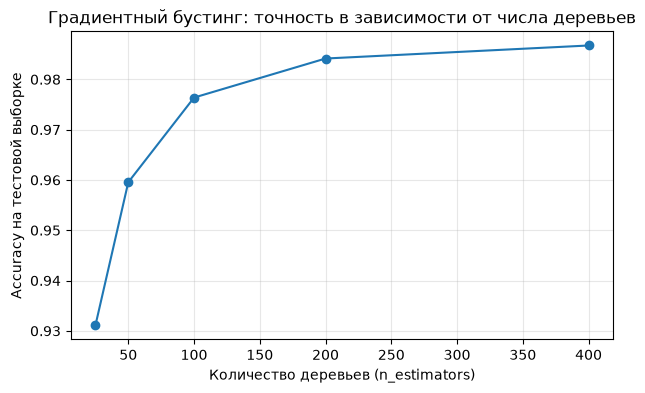

In [9]:
ax = gb_accuracy.plot(marker='o', figsize=(7, 4), legend=False)
ax.set(xlabel='Количество деревьев (n_estimators)', ylabel='Accuracy на тестовой выборке',
       title='Градиентный бустинг: точность в зависимости от числа деревьев')
ax.grid(alpha=0.3)
plt.show()

**Вывод по вопросу 3.** Точность на тесте растёт с увеличением числа деревьев: 0.931 (25), 0.960 (50), 0.976 (100), 0.984 (200), 0.987 (400). Каждое новое дерево исправляет ошибки предыдущих и уменьшает смещение, поэтому при `learning_rate=0.1` малого числа деревьев не хватает. После 200 деревьев прирост всего 0.003, кривая выходит на плато.

## Вопрос 4

* Используя поиск по сетке с перекрестной валидацией, постройте новый классификатор с градиентным бустингом, используя список оценок, аналогично вопросу 3. Также рассмотрите возможность изменения скоростей обучения (0,1; 0,01; 0,001 и т. д.), значения подвыборки (1,0 или 0,5) и количества максимальных признаков (1, 2 и т. д.).
* Проанализируйте параметры модели с наилучшей подгонкой.
* Рассчитайте соответствующие метрики ошибок для этой модели и проанализируйте матрицу путаницы.

**Примечание:** выполнение этого вопроса может занять некоторое время в зависимости от количества признаков, используемых в поиске по сетке. Рекомендуется начать с небольшого количества, чтобы убедиться в корректной работе, а затем добавить больше признаков. Установка параметра `max_features=4` в классификаторе с градиентным бустингом увеличит скорость сходимости.

In [10]:
gb_param_grid = {
    'n_estimators': [100, 200, 400],
    'learning_rate': [0.1, 0.01, 0.001],
    'subsample': [1.0, 0.5],
    'max_features': [1, 2, 4],
}
gb_search = GridSearchCV(GradientBoostingClassifier(random_state=42), gb_param_grid,
                         scoring='accuracy', cv=3, n_jobs=-1)
gb_search.fit(X_train, y_train)

print('Лучшие параметры:', gb_search.best_params_)
print('Accuracy на кросс-валидации:', round(gb_search.best_score_, 4))

Лучшие параметры: {'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 400, 'subsample': 1.0}
Accuracy на кросс-валидации: 0.986


In [11]:
gb_cv_results = pd.DataFrame(gb_search.cv_results_)
gb_cv_results.sort_values('rank_test_score')[
    ['param_n_estimators', 'param_learning_rate', 'param_subsample', 'param_max_features',
     'mean_test_score', 'std_test_score', 'mean_fit_time']
].head(10).round(4)

,param_n_estimators,param_learning_rate,param_subsample,param_max_features,mean_test_score,std_test_score,mean_fit_time
16,400,0.1,1.0,4,0.9860,0.0016,29.0639
17,400,0.1,0.5,4,0.9854,0.0019,17.0491
11,400,0.1,0.5,2,0.9825,0.0006,14.3701
15,200,0.1,0.5,4,0.9810,0.0022,9.0931
14,200,0.1,1.0,4,0.9809,0.0030,14.3022
10,400,0.1,1.0,2,0.9806,0.0035,19.7637
9,200,0.1,0.5,2,0.9757,0.0017,7.4191
8,200,0.1,1.0,2,0.9754,0.0031,10.2829
5,400,0.1,0.5,1,0.9753,0.0042,11.4566
4,400,0.1,1.0,1,0.9728,0.0007,15.0399


In [12]:
gb_cv_results.pivot_table(index='param_learning_rate', columns='param_n_estimators',
                          values='mean_test_score', aggfunc='max').round(4)

param_n_estimators,100,200,400
param_learning_rate,,,
0.001,0.7857,0.8369,0.8645
0.010,0.8982,0.9240,0.9501
0.100,0.9728,0.9810,0.9860


**Анализ лучших параметров.** Поиск по сетке перебрал 54 комбинации с 3-блочной кросс-валидацией на обучающей выборке. Лучшая модель: `learning_rate=0.1`, `n_estimators=400`, `max_features=4`, `subsample=1.0`, accuracy на кросс-валидации 0.986.

- **Скорость обучения и число деревьев связаны.** При `learning_rate=0.001` модели со 100-400 деревьями дают только 0.786-0.864 (модель недообучена), при 0.01 максимум 0.950. Чем меньше шаг, тем больше нужно деревьев.
- **`max_features`.** Чем больше признаков рассматривается при разбиении, тем выше качество: 1 признак - 0.975, 2 - 0.983, 4 - 0.986 (лучшие значения при `learning_rate=0.1` и 400 деревьях).
- **`subsample`.** При 0.5 точность почти такая же (0.9854 против 0.9860), а обучение примерно в 1.5 раза быстрее.
- **Границы сетки.** Лучшие значения `learning_rate`, `n_estimators` и `max_features` оказались крайними в сетке, поэтому при больших значениях, скорее всего, можно получить ещё небольшой прирост, но обучение будет дольше.

Показатели ошибок. Отчет о классификации особенно удобен в случаях с несколькими классами.

In [13]:
gb_best = gb_search.best_estimator_
predictions = {'GradientBoosting': gb_best.predict(X_test)}
print(classification_report(y_test, predictions['GradientBoosting'], target_names=class_names, digits=3))

                    precision    recall  f1-score   support

            LAYING      1.000     1.000     1.000       597
           SITTING      0.970     0.966     0.968       563
          STANDING      0.969     0.969     0.969       547
           WALKING      0.996     0.998     0.997       539
WALKING_DOWNSTAIRS      0.998     0.995     0.996       420
  WALKING_UPSTAIRS      0.991     0.995     0.993       424

          accuracy                          0.987      3090
         macro avg      0.987     0.987     0.987      3090
      weighted avg      0.987     0.987     0.987      3090



Матрица путаницы. Обратите внимание, что модель с градиентным бустингом испытывает небольшие затруднения при различении классов активности 1 и 2.

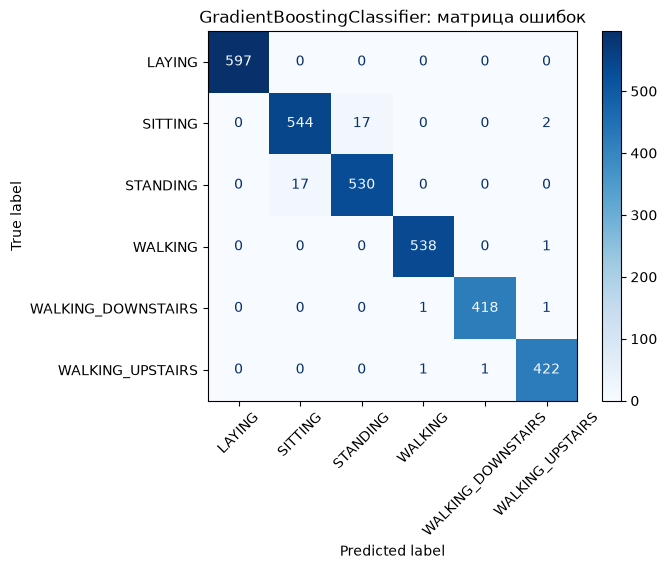

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions['GradientBoosting'], display_labels=class_names,
                                        xticks_rotation=45, cmap='Blues')
plt.title('GradientBoostingClassifier: матрица ошибок')
plt.show()

**Вывод по метрикам градиентного бустинга.** На тестовой выборке accuracy = 0.987, macro-F1 = 0.987. Класс LAYING распознаётся без ошибок, классы движения (3-5) с F1 не ниже 0.993. 34 из 41 ошибки приходятся на классы SITTING и STANDING (по 17 в каждую сторону), F1 для них 0.968-0.969. Сидя и стоя сигналы акселерометра и гироскопа очень похожи, поэтому классы 1 и 2 модель различает хуже всего.

## Вопрос 5

* Создайте модель AdaBoost и подстройте её с помощью поиска по сетке, аналогично вопросу 4. Попробуйте использовать различные значения оценщика в диапазоне от 100 до 200.
* Сравните погрешности модели AdaBoost с погрешностями модели GradientBoostedClassifier.

**ПРИМЕЧАНИЕ:** Установка параметра `max_features=4` в классификаторе на основе дерева решений, используемом в качестве базового классификатора для AdaBoost, повысит скорость сходимости.

In [15]:
ada_param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [1.0, 0.1, 0.01],
    'estimator__max_depth': [1, 3, 5, None],
}
ada_search = GridSearchCV(
    AdaBoostClassifier(DecisionTreeClassifier(max_features=4), random_state=42),
    ada_param_grid, scoring='accuracy', cv=3, n_jobs=-1,
)
ada_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",AdaBoostClass...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator__max_depth': [1, 3, ...], 'learning_rate': [1.0, 0.1, ...], 'n_estimators': [100, 150, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: in

Лучшая модель.

In [16]:
ada_best = ada_search.best_estimator_
print('Лучшие параметры:', ada_search.best_params_)
print('Accuracy на кросс-валидации:', round(ada_search.best_score_, 4))
print('Число деревьев в ансамбле:', len(ada_best.estimators_))

Лучшие параметры: {'estimator__max_depth': 5, 'learning_rate': 0.1, 'n_estimators': 200}
Accuracy на кросс-валидации: 0.9745
Число деревьев в ансамбле: 200


In [17]:
ada_cv_results = pd.DataFrame(ada_search.cv_results_)
ada_max_depth = ada_cv_results['param_estimator__max_depth'].fillna('None').astype(str)
ada_cv_results.groupby(ada_max_depth)['mean_test_score'].max().round(4)

param_estimator__max_depth
1       0.5701
3       0.9552
5       0.9745
None    0.7661
Name: mean_test_score, dtype: float64

Показатели ошибок. Обратите внимание, что проблемы с классами 1 и 2, по-видимому, усугубились и теперь затрагивают также класс 0. Также обратите внимание на другие проблемы, связанные с классами 3–5. Алгоритм AdaBoost очень чувствителен к выбросам, поэтому именно в этом может заключаться причина проблемы.

In [18]:
predictions['AdaBoost'] = ada_best.predict(X_test)
print(classification_report(y_test, predictions['AdaBoost'], target_names=class_names, digits=3))

                    precision    recall  f1-score   support

            LAYING      0.998     0.998     0.998       597
           SITTING      0.964     0.948     0.956       563
          STANDING      0.950     0.963     0.956       547
           WALKING      0.994     0.996     0.995       539
WALKING_DOWNSTAIRS      0.993     0.988     0.990       420
  WALKING_UPSTAIRS      0.986     0.991     0.988       424

          accuracy                          0.980      3090
         macro avg      0.981     0.981     0.981      3090
      weighted avg      0.980     0.980     0.980      3090



In [19]:
def error_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
    return {'accuracy': accuracy_score(y_true, y_pred), 'precision': precision, 'recall': recall, 'f1': f1}


pd.DataFrame({name: error_metrics(y_test, predictions[name]) for name in ['GradientBoosting', 'AdaBoost']}).T.round(4)

,accuracy,precision,recall,f1
GradientBoosting,0.9867,0.9872,0.9873,0.9872
AdaBoost,0.9803,0.9808,0.9809,0.9808


**Вывод по вопросу 5.** Лучшая модель AdaBoost: деревья глубины 5, `learning_rate=0.1`, 200 деревьев, accuracy на кросс-валидации 0.9745 (у градиентного бустинга 0.986).

Сильнее всего на качество влияет глубина базового дерева:
- **Решающие пни (`max_depth=1`)** дают только 0.570, для 6 классов один порог по одному признаку слишком слабый классификатор.
- **Полностью выращенное дерево (`max_depth=None`)** уже на первой итерации не ошибается на обучающей выборке, поэтому AdaBoost останавливается после одного дерева. В итоге получается одно дерево с accuracy около 0.77 на кросс-валидации при любом `learning_rate`.

На тесте у AdaBoost accuracy 0.980 и macro-F1 0.981, у градиентного бустинга 0.987 и 0.987. У AdaBoost сильнее путаются классы 1 и 2 (F1 0.956 против 0.968-0.969), появилась ошибка на классе 0 (F1 0.998 вместо 1.000), и немного хуже стали классы 3-5 (F1 0.988-0.995 против 0.993-0.997). AdaBoost сильно увеличивает веса неправильно классифицированных объектов, поэтому чувствителен к выбросам и сложным объектам на границе классов, а градиентный бустинг штрафует их мягче.

## Вопрос 6

* Постройте модель логистической регрессии с регуляризацией. Это может быть аналог модели, которая хорошо себя показала в упражнениях 4-й недели.
* Используя `VotingClassifier`, постройте модель логистической регрессии вместе с моделью GratientBoostedClassifier или AdaBoost (или обеими) из вопросов 4 и 5.
* Определите ошибку, как и ранее, и сравните результаты с соответствующими моделями с градиентным бустингом.
* Постройте матрицу путаницы для лучшей модели, созданной в этом наборе упражнений.

In [20]:
lr_model = LogisticRegressionCV(Cs=10, cv=4, l1_ratios=(0,), scoring='accuracy', max_iter=1000,
                                n_jobs=-1, use_legacy_attributes=False)
lr_model.fit(X_train, y_train)
predictions['LogisticRegression'] = lr_model.predict(X_test)
print('Выбранное C:', lr_model.C_)

Выбранное C: 2.782559402207126


Проверьте ошибки и матрицу путаницы для модели логистической регрессии.

                    precision    recall  f1-score   support

            LAYING      1.000     1.000     1.000       597
           SITTING      0.959     0.952     0.955       563
          STANDING      0.958     0.958     0.958       547
           WALKING      0.993     0.998     0.995       539
WALKING_DOWNSTAIRS      1.000     0.990     0.995       420
  WALKING_UPSTAIRS      0.984     0.995     0.989       424

          accuracy                          0.982      3090
         macro avg      0.982     0.982     0.982      3090
      weighted avg      0.982     0.982     0.982      3090



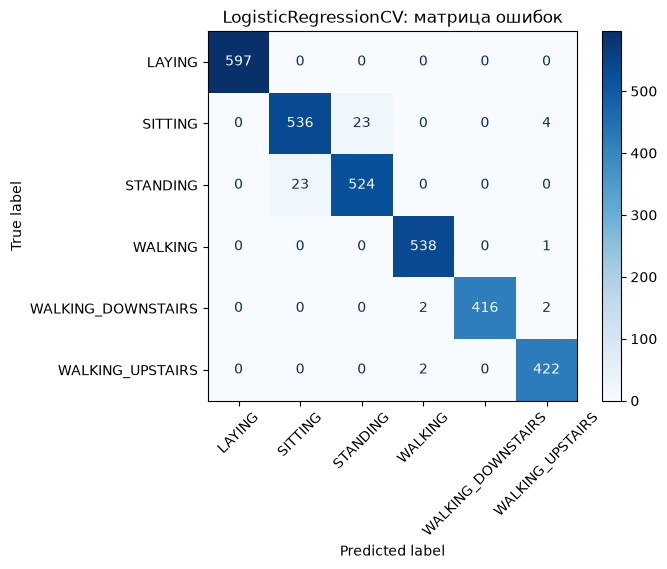

In [21]:
print(classification_report(y_test, predictions['LogisticRegression'], target_names=class_names, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, predictions['LogisticRegression'], display_labels=class_names,
                                        xticks_rotation=45, cmap='Blues')
plt.title('LogisticRegressionCV: матрица ошибок')
plt.show()

**Логистическая регрессия.** `LogisticRegressionCV` с L2-регуляризацией выбрала `C` примерно 2.78 по 4-блочной кросс-валидации на обучающей выборке. На тесте accuracy = 0.982, macro-F1 = 0.982, то есть модель уступает градиентному бустингу всего 0.005. Ошибки в основном в той же паре SITTING и STANDING (по 23 в каждую сторону), остальные классы распознаются почти без ошибок.

А теперь — многоуровневая модель (stacked model).

In [22]:
voting_model = VotingClassifier(estimators=[('lr', lr_model), ('gb', gb_best)], voting='soft', n_jobs=-1)
voting_model.fit(X_train, y_train)
predictions['Voting (LR + GB)'] = voting_model.predict(X_test)
print(classification_report(y_test, predictions['Voting (LR + GB)'], target_names=class_names, digits=3))

                    precision    recall  f1-score   support

            LAYING      1.000     1.000     1.000       597
           SITTING      0.973     0.959     0.966       563
          STANDING      0.966     0.973     0.969       547
           WALKING      0.996     0.998     0.997       539
WALKING_DOWNSTAIRS      1.000     0.998     0.999       420
  WALKING_UPSTAIRS      0.988     0.998     0.993       424

          accuracy                          0.987      3090
         macro avg      0.987     0.988     0.987      3090
      weighted avg      0.987     0.987     0.987      3090



**Ансамбль.** `VotingClassifier` с `voting='soft'` усредняет вероятности классов, которые предсказывают логистическая регрессия и градиентный бустинг. В отличие от стекинга (`StackingClassifier`), здесь нет метамодели, которая обучается на предсказаниях базовых моделей. В ансамбль взяли две разные по устройству модели: линейную и ансамбль деревьев. Из бустингов выбрали градиентный, так как на кросс-валидации он лучше AdaBoost (0.986 против 0.9745). Голосование мягкое, потому что при двух моделях жёсткое голосование не может разрешить спорные случаи.

Наконец, рассмотрим ошибку классификатора при голосовании. Здесь мы показываем немного лучшие результаты, чем при использовании либо логистической регрессии, либо градиентных бустеров по отдельности. Однако тот факт, что логистическая регрессия демонстрирует почти такие же результаты, как и градиентные бустеры, служит важным напоминанием о том, что сначала следует пробовать самую простую модель. В некоторых случаях её эффективности будет вполне достаточно.

In [23]:
comparison = pd.DataFrame({name: error_metrics(y_test, y_pred) for name, y_pred in predictions.items()}).T
comparison = comparison.sort_values(['accuracy', 'f1'], ascending=False)
comparison.round(4)

,accuracy,precision,recall,f1
Voting (LR + GB),0.9867,0.9872,0.9875,0.9873
GradientBoosting,0.9867,0.9872,0.9873,0.9872
LogisticRegression,0.9816,0.9822,0.9823,0.9822
AdaBoost,0.9803,0.9808,0.9809,0.9808


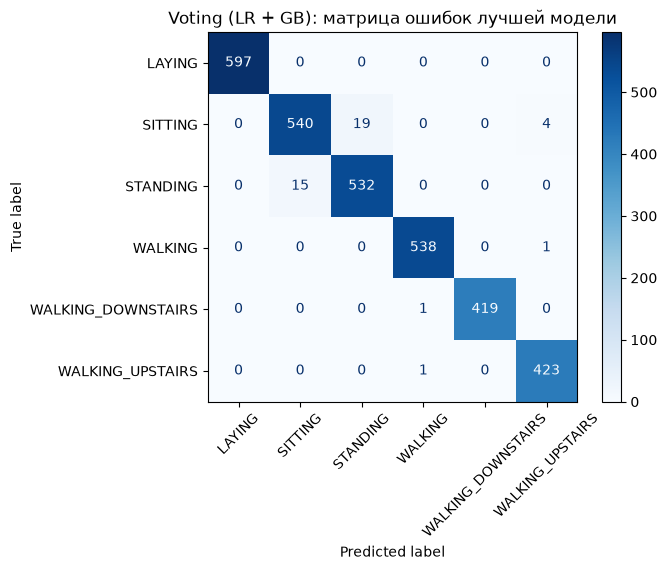

In [24]:
best_model_name = comparison.index[0]
ConfusionMatrixDisplay.from_predictions(y_test, predictions[best_model_name], display_labels=class_names,
                                        xticks_rotation=45, cmap='Blues')
plt.title(f'{best_model_name}: матрица ошибок лучшей модели')
plt.show()

**Итоговый вывод по вопросу 6.**

| Модель | Accuracy | macro-F1 |
|---|---|---|
| Voting (LR + GB) | 0.9867 | 0.9873 |
| GradientBoosting | 0.9867 | 0.9872 |
| LogisticRegression | 0.9816 | 0.9822 |
| AdaBoost | 0.9803 | 0.9808 |

- **Голосование и градиентный бустинг** по accuracy совпадают: обе модели ошибаются на 41 объекте из 3090, хотя предсказания у них отличаются на 24 объектах. Голосование стоит первым только из-за чуть большего macro-F1 (на 0.0001), эта разница появилась из-за того, что ошибки распределились по классам немного по-другому. Голосование уменьшило число ошибок с WALKING_DOWNSTAIRS (с 3 до 1), но случаев, когда SITTING предсказывается как WALKING_UPSTAIRS, стало в 2 раза больше (с 2 до 4, их добавила логистическая регрессия), а число ошибок между SITTING и STANDING не изменилось (34). При одинаковом качестве лучше использовать более простую модель, то есть один градиентный бустинг.
- **Логистическая регрессия** почти не уступает бустингу (0.982 против 0.987) и при этом обучается намного проще и быстрее, поэтому начинать стоит с простой модели.
- **AdaBoost** показал худший результат среди всех моделей.
- **Матрица ошибок лучшей модели.** Почти все ошибки - это путаница между SITTING и STANDING (19 + 15), ещё 4 объекта SITTING модель отнесла к WALKING_UPSTAIRS. Остальные классы распознаются практически без ошибок.